In [2]:
from experiment_tracking.exp_tracker import fetch_experiment_results
import pandas as pd
from datasets.Harmonized_Datasets import harmonize
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report
import yaml
import pickle
import numpy as np
import shap
import gseapy as gp
import kaplanmeier as km
from sklearn.preprocessing import StandardScaler

/home/braemp4/.cache/pypoetry/virtualenvs/venetoclax-project-wl4ICAB4-py3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
def plot_roc_auc_curve(y_true, y_prob):
 
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_score = roc_auc_score(y_true, y_prob)

    plt.tight_layout(pad=5)
    plt.plot(fpr, tpr, label=f"AUC: {round(auc_score, 3)}", linewidth=2, color="lightblue")
    plt.plot([0,1], [0,1], color="salmon", label="AUC: 0.5", linestyle="dashed")
    plt.legend(loc=4)
    plt.xlabel("fpr")
    plt.ylabel("tpr")
    plt.yticks(rotation=0)


def plot_confusion_matrix(y_true, y_pred):

    conf_matrix = confusion_matrix(y_true, y_pred)
    sns.heatmap(conf_matrix, annot=True, fmt="g", cmap=sns.color_palette("Blues", as_cmap=True))
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

 
   

   

In [3]:
datasets = harmonize()

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [6]:
# theres a bug there evestarts w t11_14_gene_modules
res_dir = "../../outputs/experiments/top_anova_features2026-09-04_23:31:24/"
moffitt_cv = "../../outputs/cv_moffitt_top_fts_2026_09_05/results.csv" #
gmt_dir = "../../data/GMT/"
hallmark_gmt = gmt_dir + "h.all.v2026.1.Hs.symbols.gmt"

ev_metrics = pd.read_csv(res_dir + 'ev_metrics.csv')
ev_results = pd.read_csv(res_dir + 'ev_results.csv')
cv_results = pd.read_csv(moffitt_cv)
top_fts = pd.read_csv("../../outputs/top_ft_sens/top_ft_sens/results.csv")


In [451]:
with open(res_dir + "experiment_parameters.yaml", "rb") as f:
    params = yaml.safe_load(f)

In [452]:
params

{'cv_splits': 2,
 'date_timestamp': '2026-09-04 23:31:24',
 'feature_engineering': {'cache_feature_transformation': True,
  'method': 'top_ft_sens',
  'n_features': 100,
  'output_dir': 'top_ft_sens'},
 'ml_model': 'LogisticRegression(random_state=4)',
 'model_path': '/home/braemp4/Code/venetoclax_project/models/top_anova_features2026-09-04_23:31:24.pkl',
 'random_state': 4,
 'title': 'top_anova_features'}

In [453]:
top_anova_df = pd.read_csv("../../outputs/top_ft_sens/top_ft_sens/results.csv")

In [454]:
top_anova_df = top_anova_df.sort_values(by='score', ascending=False)

In [455]:
top_fts = top_anova_fts.iloc[:100]['feature']
top_fts

0        UGT8
1      KCNK15
2     FAM151B
3       LTBP4
4       BCAR1
       ...   
95    BLOC1S4
96    TNFSF11
97     ATP1B3
98    PIK3C2B
99       DAZ1
Name: feature, Length: 100, dtype: str

In [456]:
ml_model_path = params['model_path']
with open(ml_model_path, "rb") as f:
    ml_model = pickle.load(f)

ml_model

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",4
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver

In [457]:
feature_weights_df = pd.DataFrame([ml_model.feature_names_in_, ml_model.coef_[0]], index=['feature', 'weight']).transpose()
feature_weights_df = feature_weights_df.sort_values(by="weight", ascending=True)

# top features according to weights
print(feature_weights_df.head(10))
print(feature_weights_df.tail(10))

   feature    weight
91   PAQR5 -0.346202
75  TMEFF1 -0.315718
88   AP3B2 -0.312516
32   GTSF1 -0.301777
39    CCR1 -0.298177
80   ESRRG -0.264933
96    CTSV -0.259123
40  POLR3G  -0.25753
19   EVA1A -0.256691
24   TNIP3 -0.255626
    feature    weight
62   RNF208  0.233143
17     PFN2  0.237793
48   ARID5B  0.245807
28  CCDC148  0.290242
86    SATB2  0.304583
44    GGACT  0.314115
61     ANK3  0.391785
95   KCNK15  0.528244
64  FAM151A  0.541431
46    PCDH8  0.554463


In [458]:
feature_weights_df['abs_weight'] = np.abs(feature_weights_df['weight'])
feature_weights_df = feature_weights_df.sort_values(by="abs_weight", ascending=False)

<Axes: xlabel='feature', ylabel='abs_weight'>

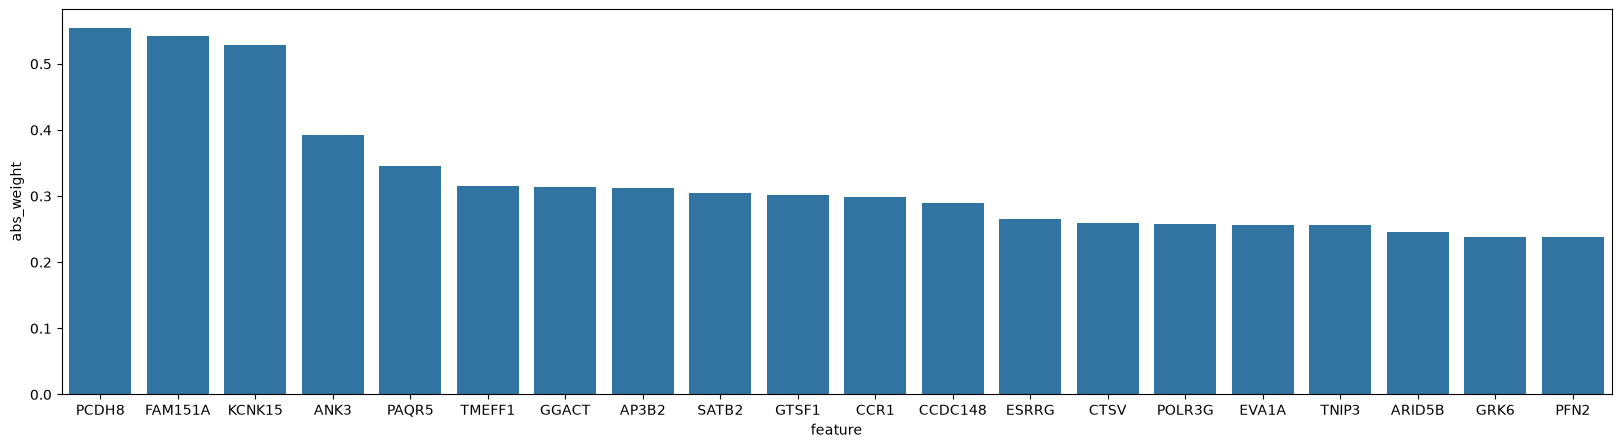

In [459]:
fig, ax = plt.subplots(1, figsize=(20,5))
sns.barplot(feature_weights_df.head(20), y='abs_weight',x='feature')
# TNIP3 - Nf-kb signaling inhibitor

<Axes: xlabel='feature', ylabel='score'>

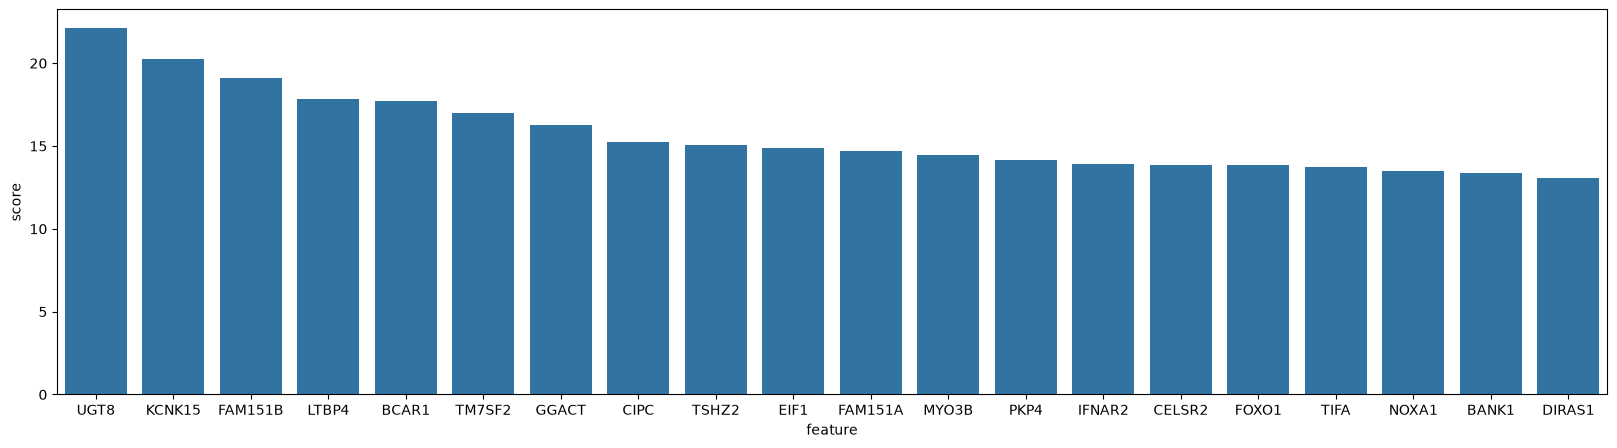

In [460]:
top_anova_df.head(20)

fig, ax = plt.subplots(1, figsize=(20,5))
sns.barplot(top_anova_df.head(20), y='score',x='feature')
# noxa here too

In [461]:
X_train, X_test = datasets["Moffitt"][:,top_fts], datasets["Decampos"][:,top_fts]

In [462]:
explainer = shap.LinearExplainer(ml_model, X_train.to_df(), max_samples=111)
shap_values = explainer(X_test.to_df())

Background dataset has 111 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=111 when initializing the masker.


In [463]:
shap_values.feature_names
shap_values.values

mean_shap = [np.mean(shap_values.values[i]) for i in range(len(shap_values))]

shap_results = pd.DataFrame([shap_values.feature_names, mean_shap], index=['feature', 'score']).transpose()
shap_results = shap_results[shap_results['score'].notna()]
shap_results['abs_score'] = np.abs(shap_results['score'])
shap_results = shap_results.sort_values(by='abs_score', ascending=False)
len(shap_results)



38

**Get enrichment of important features**

In [464]:
k = 100
anova_enr = gp.enrich(gene_list=top_anova_df.head(k)['feature'], gene_sets=hallmark_gmt, background=None, outdir=None)
model_enr = gp.enrich(gene_list=feature_weights_df.head(k)['feature'], gene_sets=hallmark_gmt, background=None, outdir=None) # this already has 100 features
shap_enr = gp.enrich(gene_list=shap_results['feature'],gene_sets=hallmark_gmt,background=None, outdir=None) # this is like 38 features - out of the 100 from the model

In [465]:
anova_enr.results

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ADIPOGENESIS,1/200,0.730602,0.730602,1.136705,0.356796,ATP1B3
1,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ALLOGRAFT_REJECTION,2/200,0.367690,0.730602,1.976379,1.977399,IFNAR2;CCR1
2,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ANDROGEN_RESPONSE,2/101,0.135110,0.472884,4.036693,8.080116,B4GALT1;ARID5B
3,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_APICAL_JUNCTION,3/200,0.133210,0.472884,2.890692,5.827130,MAPK13;B4GALT1;MDK
4,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_APICAL_SURFACE,1/44,0.246721,0.628017,5.408777,7.569571,B4GALT1
5,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_BILE_ACID_METABOLISM,1/112,0.516592,0.730602,2.076885,1.371786,NEDD4
6,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_CHOLESTEROL_HOMEOSTASIS,2/74,0.080165,0.472884,5.575146,14.069848,TM7SF2;ALCAM
7,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COAGULATION,1/138,0.592768,0.730602,1.673851,0.875345,CTSV
8,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COMPLEMENT,1/200,0.730602,0.730602,1.136705,0.356796,CTSV
9,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,1/200,0.730602,0.730602,1.136705,0.356796,PFN2


In [466]:
model_enr.results

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ADIPOGENESIS,1/200,0.730602,0.730602,1.136705,0.356796,ATP1B3
1,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ALLOGRAFT_REJECTION,2/200,0.367690,0.730602,1.976379,1.977399,IFNAR2;CCR1
2,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ANDROGEN_RESPONSE,2/101,0.135110,0.472884,4.036693,8.080116,B4GALT1;ARID5B
3,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_APICAL_JUNCTION,3/200,0.133210,0.472884,2.890692,5.827130,MAPK13;B4GALT1;MDK
4,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_APICAL_SURFACE,1/44,0.246721,0.628017,5.408777,7.569571,B4GALT1
5,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_BILE_ACID_METABOLISM,1/112,0.516592,0.730602,2.076885,1.371786,NEDD4
6,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_CHOLESTEROL_HOMEOSTASIS,2/74,0.080165,0.472884,5.575146,14.069848,TM7SF2;ALCAM
7,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COAGULATION,1/138,0.592768,0.730602,1.673851,0.875345,CTSV
8,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COMPLEMENT,1/200,0.730602,0.730602,1.136705,0.356796,CTSV
9,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,1/200,0.730602,0.730602,1.136705,0.356796,PFN2


In [467]:
shap_enr.results

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ALLOGRAFT_REJECTION,1/200,0.455492,0.455492,2.509774,1.973632,IFNAR2
1,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_CHOLESTEROL_HOMEOSTASIS,2/74,0.019441,0.330493,12.892054,50.799629,TM7SF2;ALCAM
2,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COAGULATION,1/138,0.340566,0.455492,3.695564,3.980660,CTSV
3,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_COMPLEMENT,1/200,0.455492,0.455492,2.509774,1.973632,CTSV
4,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,1/200,0.455492,0.455492,2.509774,1.973632,PFN2
5,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ESTROGEN_RESPONSE_EARLY,2/200,0.116153,0.394919,4.570693,9.840017,CELSR2;KCNK15
6,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_ESTROGEN_RESPONSE_LATE,1/200,0.455492,0.455492,2.509774,1.973632,CELSR2
7,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_IL2_STAT5_SIGNALING,1/199,0.453795,0.455492,2.523023,1.993466,ALCAM
8,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_INTERFERON_GAMMA_RESPONSE,2/200,0.116153,0.394919,4.570693,9.840017,IFNAR2;BANK1
9,h.all.v2026.1.Hs.symbols.gmt,HALLMARK_KRAS_SIGNALING_DN,2/200,0.116153,0.394919,4.570693,9.840017,CELSR2;SERPINA10


- No pathways are significantly enriched from our top predictive genes. This makes sense because we used a very small feature set so we don't have enough info to see if a full pathway is enriched. 
- This is just from hallmark so I should try the other ones when I get to differential expression analysis. 

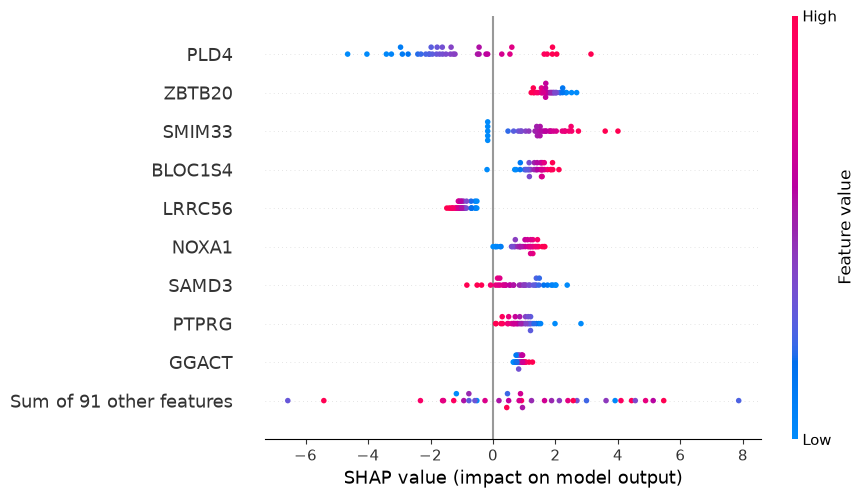

In [468]:

shap.plots.beeswarm(shap_values)
# NOXA!! (atleast in this run) pro-apoptotic protein

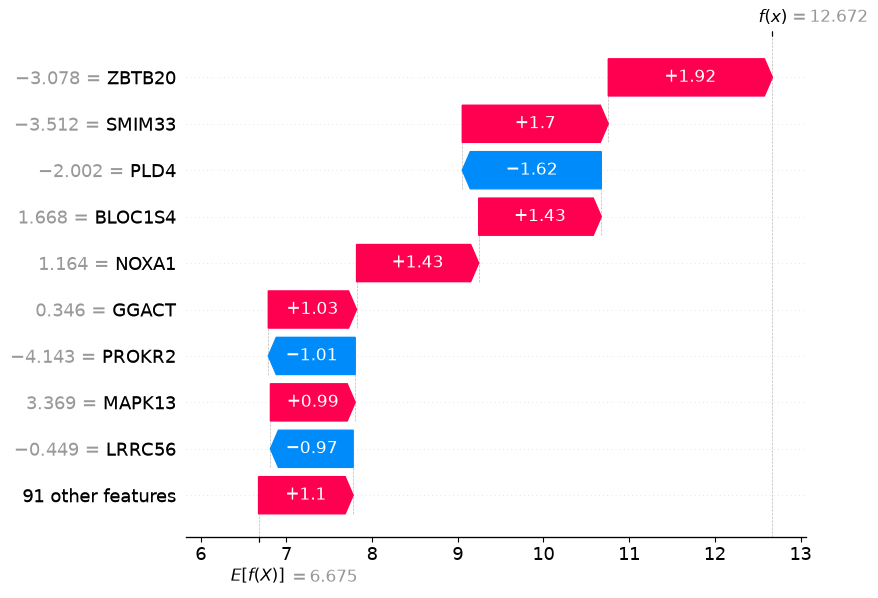

In [469]:
sample = 'SRR11586876'

shap.plots.waterfall(shap_values[5])

**Survival Analysis**


In [48]:
mf_ad = datasets["Moffitt"]
survival_df = pd.read_excel("../../data/Moffitt/Clinical_Metadata/can-26-1082_table_s10_suppst10.xlsx")
survival_df.columns = survival_df.iloc[0]
survival_df = survival_df.set_index("RNAseq_SLID")

#survival_df = survival_df.drop(index=1)

survival_df = survival_df.loc[~survival_df.index.duplicated(keep="first")]


**Sample Purity could explain tricky predictions**

In [ ]:
survival_df[survival_df['Sample_Purity'] == "Low"] #

,Disease_status,PlasmaCells_CIBERSORT,PlasmaCells_xCell,Sample_Purity,PC1_coordinate,PC2_coordinate,PC1>0,Quadrant,Supercluster_Alpha,Supercluster_Beta,...,TCL1A,TET2,TGDS,TP53,TRAF2,TRAF3,UBR5,XBP1,ZFP36L1,ZNF292
RNAseq_SLID,,,,,,,,,,,,,,,,,,,,,
SL204941,Early Relapse Multiple Myeloma,0.666895,0.154909,Low,NaN,NaN,NaN,NaN,0.499153,0.196157,...,no,yes,no,no,no,no,no,no,no,no
SL215227,Newly Diagnosed Multiple Myeloma,0.652539,0.163964,Low,NaN,NaN,NaN,NaN,-0.949202,-0.343268,...,no,no,no,no,no,no,no,no,no,no
SL215230,Smoldering Multiple Myeloma,0.361406,0.106758,Low,NaN,NaN,NaN,NaN,-2.923414,-0.495712,...,no,no,no,no,no,no,yes,no,no,no
SL215237,Newly Diagnosed Multiple Myeloma,0.215678,0.059789,Low,NaN,NaN,NaN,NaN,-1.381761,0.4584,...,no,no,no,no,no,no,no,no,no,no
SL215239,Newly Diagnosed Multiple Myeloma,0.015542,0,Low,NaN,NaN,NaN,NaN,-0.650885,0.877701,...,no,no,no,no,no,no,no,no,no,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SL399339,Early Relapse Multiple Myeloma,0.632486,0.169473,Low,NaN,NaN,NaN,NaN,0.022891,-0.092251,...,no,no,no,no,no,no,no,no,no,no
SL399345,Early Relapse Multiple Myeloma,0.339632,0.164943,Low,NaN,NaN,NaN,NaN,0.229485,0.702814,...,no,no,no,no,no,no,no,no,no,no
SL404302,Late Relapse Multiple Myeloma,0.445924,0.120897,Low,NaN,NaN,NaN,NaN,0.327981,0.933021,...,no,no,no,no,no,no,no,no,no,no


In [472]:
patient_index = list(set(mf_ad.to_df().index) & set(survival_df.index))
survival_df = survival_df[['OS_days', 'OS_status', 'PFS_days', "PFS_status"]].loc[patient_index]

In [473]:
# OS
os_df = survival_df[survival_df[['OS_days', "OS_status"]].notna()]
os_df['OS_status'] = [1 if s == 'alive' else 0 for s in os_df['OS_status']]

In [474]:
os_df

,OS_days,OS_status,PFS_days,PFS_status
RNAseq_SLID,,,,
SL405730,315,1,NaN,NaN
SL242358,832,1,NaN,NaN
SL375777,588,1,NaN,NaN
SL405605,419,1,NaN,NaN
SL375781,301,0,NaN,NaN
...,...,...,...,...
SL242345,1150,1,NaN,NaN
SL399354,197,1,NaN,NaN
SL250173,499,0,NaN,NaN


In [475]:
cv_results

,Unnamed: 0,samples,y_true,y_pred,y_prob
0,0,SL399348,1,0,0.400009
1,1,SL414057,0,0,0.400009
2,2,SL432590,1,0,0.400009
3,3,SL399327,0,0,0.400009
4,4,SL405631,1,0,0.400009
...,...,...,...,...,...
106,106,SL405724,0,0,0.014101
107,107,SL432584,1,0,0.165904
108,108,SL240795,0,0,0.013937
109,109,SL240938,1,1,0.817524


In [476]:
# very bad cv performance - this model probably isn't better than Moffitt FISH labels but we can check
print(classification_report(cv_results["y_true"], cv_results["y_pred"]))
print(roc_auc_score(cv_results["y_true"], cv_results["y_prob"]))

              precision    recall  f1-score   support

           0       0.62      0.94      0.75        67
           1       0.60      0.14      0.22        44

    accuracy                           0.62       111
   macro avg       0.61      0.54      0.49       111
weighted avg       0.61      0.62      0.54       111

0.5636024423337855


<Axes: xlabel='ABT-199', ylabel='Count'>

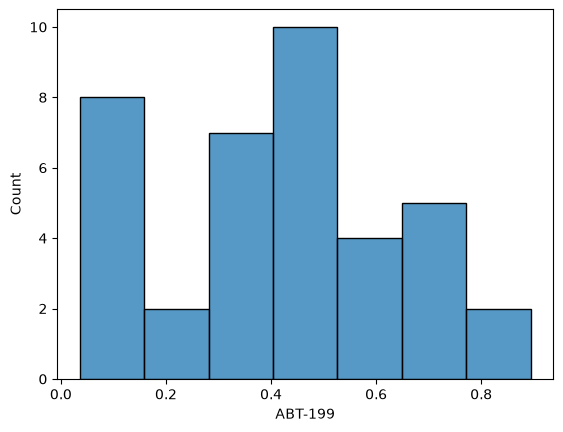

In [477]:
sns.histplot(datasets['Decampos'].obs['ABT-199'])

<Axes: xlabel='ABT-199', ylabel='Count'>

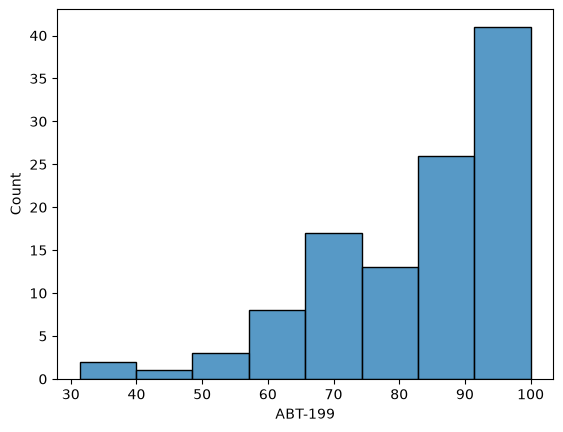

In [44]:
sns.histplot(datasets['Moffitt'].obs['ABT-199'])

- one benefit with this top feature strategy is we can predict sensitivity in the commpass dataset which is unseen by selectkbest
- its ez to run survival analysis and deseq in commpass
- The main downside is it is hard to determine is the model is better than FISH
    - **we could have to run selectkbest inside cross validation and get predictions within moffitt. Ideally use "leave-one-out" cross validation. Then compare FISH labels to total preds using mcnemars test (no need to predict with FISH every fold).**
- barplot of top features
- gotta have SHAP analysis
- We can use enrichr, stringdb (PPIs), WGCNA (correlate wgcna module eigengenes with phenotype and predictions)
- using cv from moffitt we can get DEGs, and do GSEA and TF inference
- See if we see the same trends in the scRNAseq dataset (separate notebook for sure)



In [47]:
print(ev_metrics)

        Unnamed: 0         0
0  precision_score  0.954545
1     recall_score  0.724138
2         f1_score  0.823529
3         accuracy  0.763158
4          roc_auc  0.823755


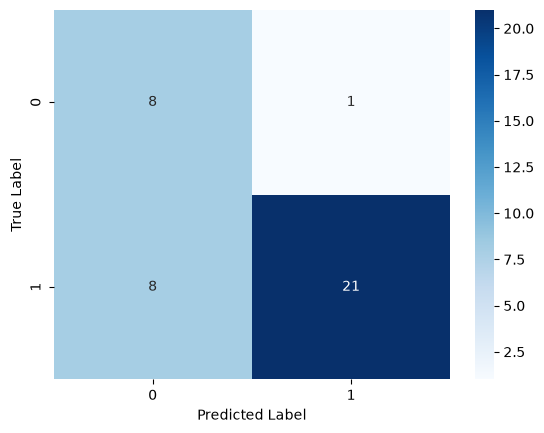

In [479]:
plot_confusion_matrix(ev_results['y_true'], ev_results['y_pred'])


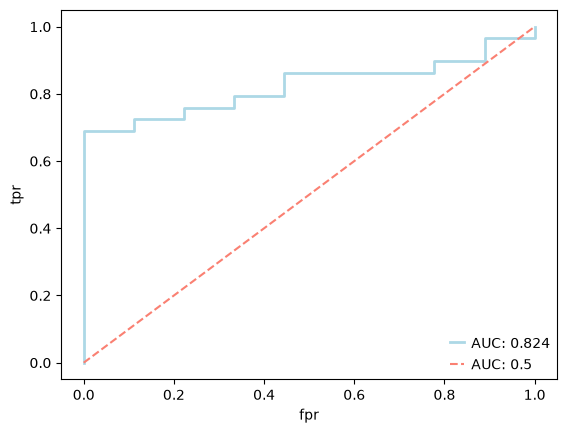

In [480]:
plot_roc_auc_curve(ev_results['y_true'], ev_results['y_prob'])



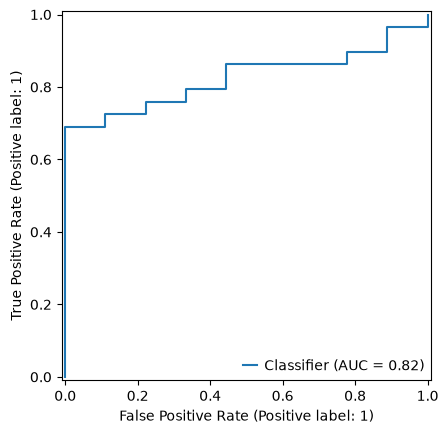

In [482]:
from sklearn.metrics import RocCurveDisplay
# lowkey cleaner
clf_disp = RocCurveDisplay.from_predictions(ev_results['y_true'], ev_results["y_prob"])

In [483]:
cv_results = cv_results.set_index("samples")

In [484]:
import pylimma
mf_ad = mf_ad[cv_results.index]
mf_ad.obs['y_pred'] = cv_results['y_pred']

pylimma.lm_fit(mf_ad, design="~ y_pred", key="fit")
pylimma.e_bayes(mf_ad, key="fit")
results_df = pylimma.top_table(mf_ad, coef=1, key="fit",number=np.inf,sort_by="p")

/tmp/ipykernel_12122/2306293068.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['y_pred'] = cv_results['y_pred']


In [485]:
results_df = results_df.sort_values(by="t")

In [487]:
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d

2026-09-05 20:18:21,567 [WARNING] Duplicated values found in preranked stats:
sample	ratio
log_fc         4.60%
ave_expr       5.21%
t              3.91%
p_value        4.06%
adj_p_value   67.66%
b              4.94%
The order of those genes will be arbitrary, which may produce unexpected results.


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,ave_expr,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_MYC_TAR...,0.728667,4.952980,0.000000,0.000000,0.0,151/193,15.90%,PPIA;RPS10;PABPC1;RPL18;RPLP0;RPS6;RPL14;HNRNP...
1,ave_expr,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_OXIDATI...,0.691918,4.592241,0.000000,0.000000,0.0,167/193,24.76%,ATP5MG;NDUFA1;COX6B1;NDUFB1;ATP5ME;UQCRB;HSPA9...
2,ave_expr,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_MTORC1_...,0.600059,4.439162,0.000000,0.000000,0.0,134/194,25.72%,PPIA;HSP90B1;CALR;CANX;GAPDH;XBP1;ALDOA;TPI1;H...
3,b,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_E2F_TAR...,0.266934,3.926863,0.000000,0.000000,0.0,169/199,53.52%,WEE1;POLD1;MCM5;POLE;MTHFD2;MCM7;LIG1;EXOSC8;M...
4,ave_expr,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_UNFOLDE...,0.613290,3.898341,0.000000,0.000000,0.0,83/112,23.52%,HSP90B1;CALR;RPS14;HERPUD1;NPM1;EEF2;XBP1;HSPA...
...,...,...,...,...,...,...,...,...,...,...
295,t,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_PANCREA...,0.153401,0.491798,0.996778,0.998864,1.0,6/40,19.63%,HNF1A;FOXO1;PAX4;CHGA;NKX2-2;DCX
296,log_fc,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_ADIPOGE...,0.118875,0.461685,1.000000,0.999741,1.0,95/196,48.84%,ADIG;PTGER3;ORM1;ADCY6;MRAP;SLC1A5;SLC25A10;OM...
297,adj_p_value,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_MYC_TAR...,0.090489,0.432770,0.997990,0.999258,1.0,35/57,70.82%,SRM;MPHOSPH10;SORD;RCL1;NOP2;MAP3K6;GNL3;MYC;W...
298,b,h.all.v2026.1.Hs.symbols.gmt__HALLMARK_FATTY_A...,-0.047669,-0.424910,1.000000,0.997378,1.0,119/152,80.65%,ECI2;AOC3;REEP6;HPGD;GPD1;HSD17B11;CYP1A1;MCEE...


In [488]:
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

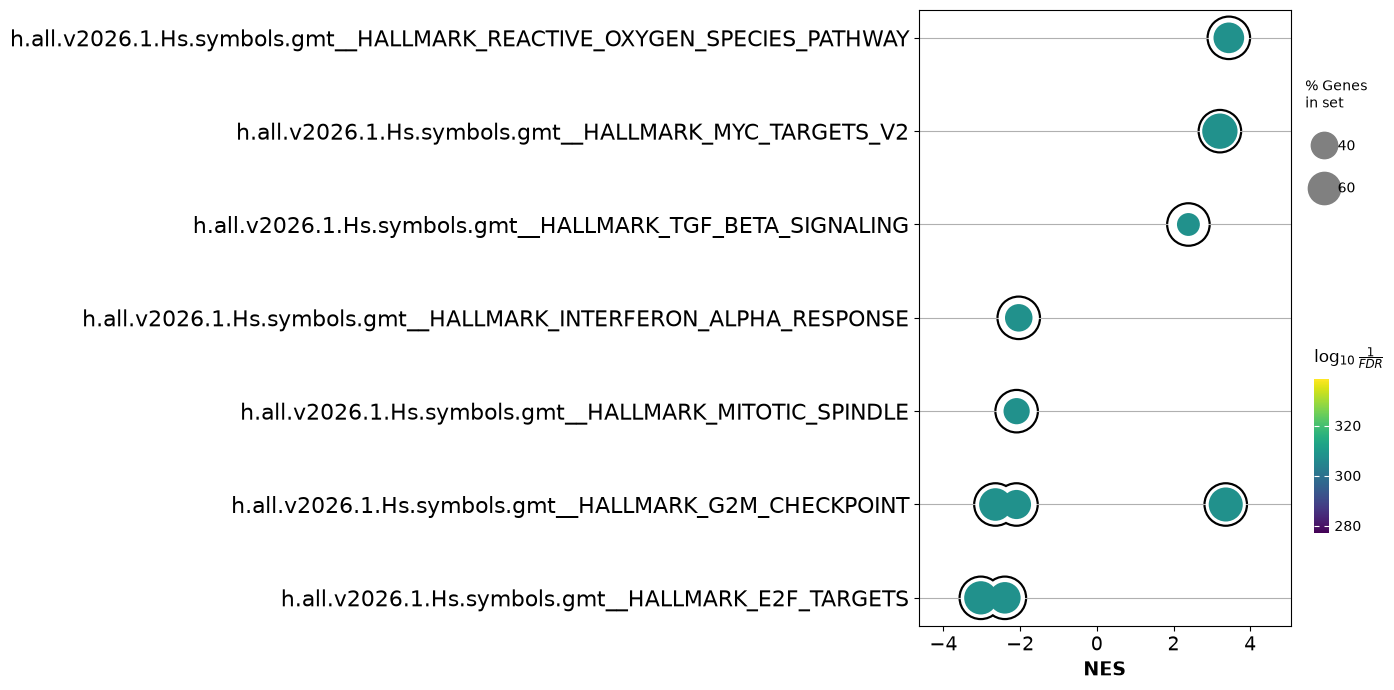

In [31]:

from gseapy import dotplot

ax = dotplot(
    pre_res.res2d,
    column="FDR q-val",
    cmap=plt.cm.viridis,
    size=5,                # dot size scaling
    figsize=(6, 8),
    cutoff=0.25,           # only show terms with FDR q-val <= cutoff
    show_ring=True,
)



In [490]:
results_df['padj'] = results_df["adj_p_value"]

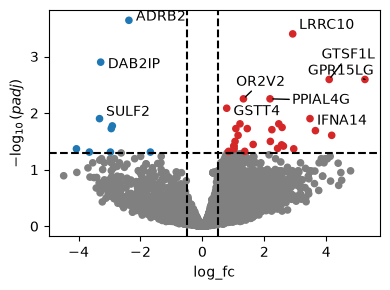

In [491]:
import decoupler as dc
# there we go 
dc.pl.volcano(data=results_df, x="log_fc", y="padj", top=10)

In [28]:
collectri = dc.op.collectri(organism='human')
collectri

,source,target,weight,resources,references,sign_decision
0,MYC,TERT,1.0,DoRothEA-A;ExTRI;HTRI;NTNU.Curated;Pavlidis202...,10022128;10491298;10606235;10637317;10723141;1...,PMID
1,SPI1,BGLAP,1.0,ExTRI,10022617,default activation
2,SMAD3,JUN,1.0,ExTRI;NTNU.Curated;TFactS;TRRUST,10022869;12374795,PMID
3,SMAD4,JUN,1.0,ExTRI;NTNU.Curated;TFactS;TRRUST,10022869;12374795,PMID
4,STAT5A,IL2,1.0,ExTRI,10022878;11435608;17182565;17911616;22854263;2...,default activation
...,...,...,...,...,...,...
42985,NFKB,hsa-miR-143-3p,1.0,ExTRI,19472311,default activation
42986,AP1,hsa-miR-206,1.0,ExTRI;GEREDB;NTNU.Curated,19721712,PMID
42987,NFKB,hsa-miR-21,1.0,ExTRI,20813833;22387281,default activation
42988,NFKB,hsa-miR-224-5p,1.0,ExTRI,23474441;23988648,default activation


In [493]:
results_df

,log_fc,ave_expr,t,p_value,adj_p_value,b,padj
gene,,,,,,,
ADRB2,-2.373823,2.569353,-6.157642,1.225364e-08,0.000229,9.055197,0.000229
DAB2IP,-3.285356,-0.249662,-5.546564,2.019169e-07,0.001257,6.590051,0.001257
SULF2,-3.322669,5.722928,-4.729166,6.713791e-06,0.012541,3.512923,0.012541
SOX30,-2.910122,-2.095204,-4.591597,1.173103e-05,0.016857,3.024393,0.016857
PPFIBP1,-2.943799,-0.039442,-4.507565,1.641575e-05,0.018804,2.730582,0.018804
...,...,...,...,...,...,...,...
PPIAL4G,2.184646,-9.550718,5.008560,2.098816e-06,0.005601,4.532550,0.005601
OR2V2,1.324832,-9.797379,5.038714,1.847092e-06,0.005601,4.644697,0.005601
GTSF1L,4.095738,-8.732923,5.271043,6.805217e-07,0.002542,5.521774,0.002542


In [494]:
input_for_tf = results_df[['t']].T.rename(index={"t": "sensitive.vs.resistant"})
input_for_tf

gene,ADRB2,DAB2IP,SULF2,SOX30,PPFIBP1,PLA2G2D,CACHD1,TLR3,LAX1,SOX5,...,LRCOL1,LITAF,WEE1,IFNA14,GSTT4,PPIAL4G,OR2V2,GTSF1L,GPR15LG,LRRC10
sensitive.vs.resistant,-6.157642,-5.546564,-4.729166,-4.591597,-4.507565,-4.120469,-4.054819,-4.052352,-4.046155,-4.008756,...,4.55782,4.632208,4.643859,4.738491,4.885783,5.00856,5.038714,5.271043,5.297598,5.889464


In [495]:
tf_acts, tf_padj = dc.mt.ulm(data=input_for_tf, net=collectri)

msk = (tf_padj.T < 0.05).iloc[:,0]
tf_acts = tf_acts.loc[:,msk]

tf_acts

,BRD4,E2F4,ETS1,GATA2,JUND,MYC,MYOCD,NFKB1
sensitive.vs.resistant,3.475776,5.565158,-3.52462,-4.68778,-3.479591,4.809868,-3.477319,-3.486


Text(0.5, 1.0, 'TF Inference')

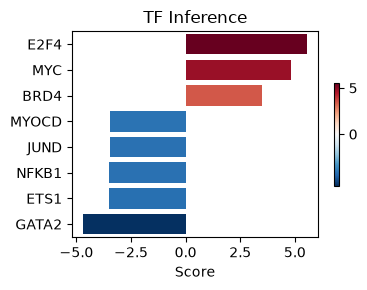

In [496]:
dc.pl.barplot(data=tf_acts, name="sensitive.vs.resistant")
plt.title("TF Inference")

I think I know whats happening!!
- resistant cells have been shown to be more differentiated
- my dataset consistently shows resistant cells have myc targets and myc tf activity 
- It could be the case that resistant cells are myc resistant. Myc signals are being overexpressed in response to the differentiated state but they do not respond. 

In [497]:
mf_ad.obs["y_true"] = cv_results['y_true']

In [498]:
mf_ad.obs

,ABT-199,ExVivo_SampleID,patientID,t11_14,y_pred,y_true
RNA_SampleID,,,,,,
SL399348,65.236880,Pt382,GDH087884bf,0.0,0,1
SL414057,86.576130,Pt419,GDH10e17fff,NaN,0,0
SL432590,66.291761,Pt506,GDH12b19f91,NaN,0,1
SL399327,90.113614,Pt387,GDH15c6174b,0.0,0,0
SL405631,82.246965,Pt401,GDH178132b2,0.0,0,1
...,...,...,...,...,...,...
SL405724,95.078404,Pt392,GDHdec9c5ce,0.0,0,0
SL432584,65.712897,Pt495,GDHe3530ae7,NaN,0,1
SL240795,88.815766,Pt143,GDHf5b6b0bc,0.0,0,0


<Axes: xlabel='y_true', ylabel='ABT-199'>

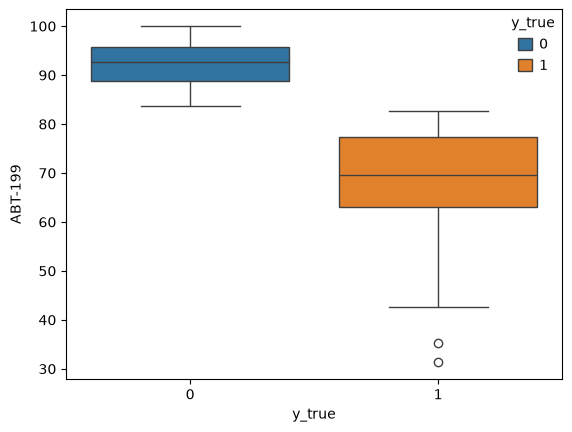

In [499]:
sns.boxplot(mf_ad.obs,y="ABT-199", x='y_true',hue='y_true')

<Axes: xlabel='y_pred', ylabel='ABT-199'>

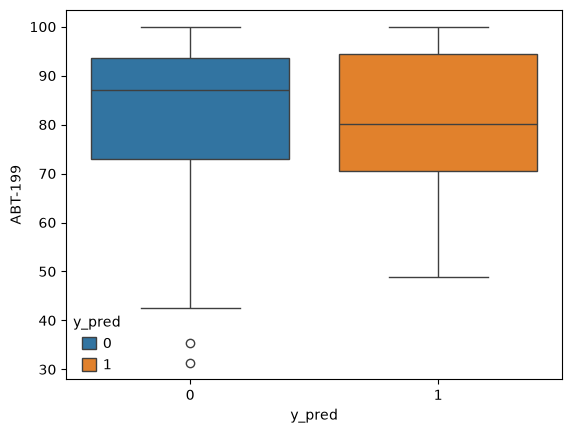

In [500]:
sns.boxplot(mf_ad.obs,y="ABT-199", x='y_pred',hue='y_pred') # thats interesting

In [9]:
dc_ad = datasets["Decampos"]
ev_results = ev_results.set_index('samples')

In [14]:
import pylimma
dc_ad = dc_ad[ev_results.index]
dc_ad.obs['y_pred'] = ev_results['y_pred']

pylimma.lm_fit(dc_ad, design="~ y_pred", key="fit")
pylimma.e_bayes(dc_ad, key="fit")
results_df = pylimma.top_table(dc_ad, coef=1, key="fit",number=np.inf,sort_by="p")

/tmp/ipykernel_19780/56003096.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  dc_ad.obs['y_pred'] = ev_results['y_pred']


In [17]:
results_df = results_df.sort_values(by="t")
results_df['padj'] = results_df['adj_p_value']

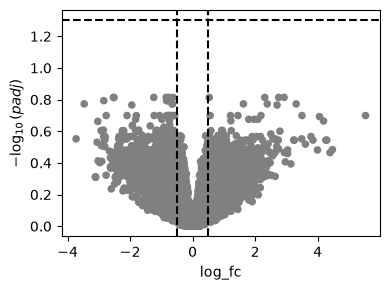

In [18]:
import decoupler as dc
# there we go 
dc.pl.volcano(data=results_df, x="log_fc", y="padj", top=10)

In [19]:
pre_res = gp.prerank(rnk=results_df, gene_sets=[hallmark_gmt], threads=8, min_size=5, max_size=1000, outdir=None, seed=4)
pre_res.res2d
pre_res.res2d = pre_res.res2d.sort_values(by="NES")

2026-09-06 07:33:57,844 [WARNING] Duplicated values found in preranked stats:
sample	ratio
log_fc         4.41%
ave_expr       4.41%
t              4.41%
p_value        4.41%
adj_p_value   78.10%
b              4.41%
padj          78.10%
The order of those genes will be arbitrary, which may produce unexpected results.


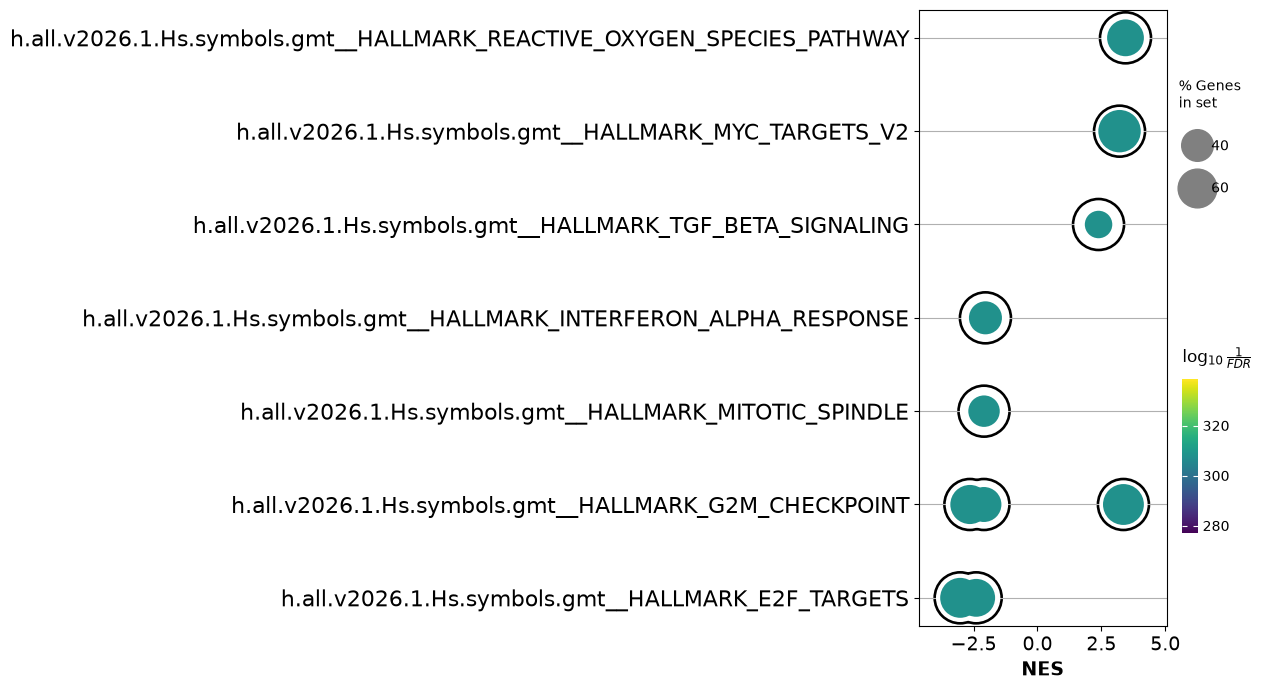

In [30]:
from gseapy import dotplot

ax = dotplot(
    pre_res.res2d,
    column="FDR q-val",
    cmap=plt.cm.viridis,
    size=6,                # dot size scaling
    figsize=(4, 8),
    cutoff=0.25,           # only show terms with FDR q-val <= cutoff
    show_ring=True,
)

Text(0.5, 1.0, 'TF Inference')

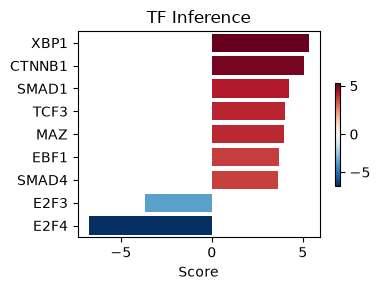

In [29]:
input_for_tf = results_df[['t']].T.rename(index={"t": "sensitive.vs.resistant"})
tf_acts, tf_padj = dc.mt.ulm(data=input_for_tf, net=collectri)

msk = (tf_padj.T < 0.05).iloc[:,0]
tf_acts = tf_acts.loc[:,msk]

dc.pl.barplot(data=tf_acts, name="sensitive.vs.resistant")
plt.title("TF Inference")

In [41]:
dc_ad.obs['y_true'] = ev_results['y_true']

<Axes: xlabel='y_pred', ylabel='ABT-199'>

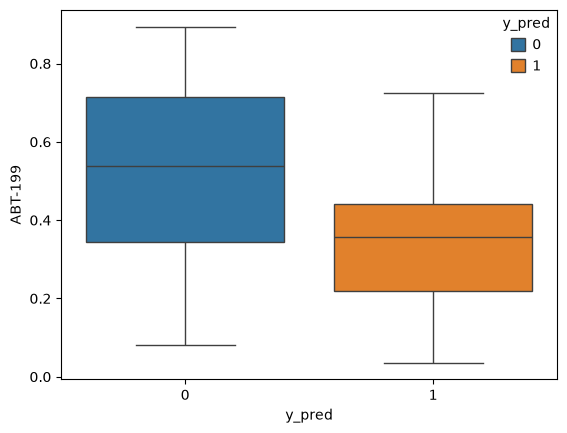

In [38]:
sns.boxplot(dc_ad.obs, y="ABT-199", x="y_pred", hue='y_pred')

<Axes: xlabel='y_true', ylabel='ABT-199'>

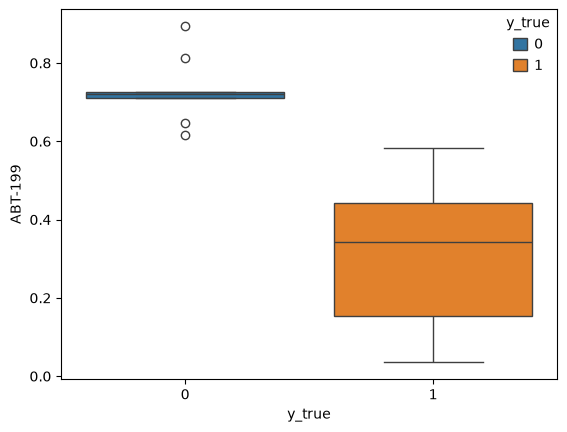

In [43]:
sns.boxplot(dc_ad.obs, y="ABT-199", x="y_true", hue='y_true')

**Deconvolution**
